# Notebook 5 — Solutions to the exercises

Model solutions for instructors and self-learners. Try the exercises in `notebooks/05_evaluation_and_pitfalls.ipynb` first.

## Setup (same as Notebook 5)

In [1]:
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import uniform_filter, gaussian_filter
from skimage.data import shepp_logan_phantom, camera
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

plt.rcParams["figure.dpi"] = 100
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # line colors, always used in this order
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}. This notebook does not train anything, so a CPU is fine.")

Using cpu. This notebook does not train anything, so a CPU is fine.


In [2]:
# ---- From Notebooks 1-3 (now working on stacks of images too) ------------------
def fft2c(image):
    """Centered, orthonormal 2D FFT over the last two axes: image(s) -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image, axes=(-2, -1)), norm="ortho"), axes=(-2, -1))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT over the last two axes: k-space -> image(s)."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace, axes=(-2, -1)), norm="ortho"), axes=(-2, -1))


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.set_title(title)
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def nrmse(recon, reference):
    """Normalized root-mean-square error: 0 is perfect, 1 is as large as the image itself."""
    return np.linalg.norm(recon - reference) / np.linalg.norm(reference)


def tidy(ax):
    """Quiet grid and axes for line plots."""
    ax.grid(alpha=0.25, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)


def variable_density_lines(N, R, center_fraction=0.08, decay=3, seed=0):
    """N // R lines: a fully sampled center, the rest random and more likely near the center."""
    rng = np.random.default_rng(seed)
    n_total = N // R
    n_center = int(round(N * center_fraction))
    lines = np.zeros(N, dtype=bool)
    lines[N // 2 - n_center // 2 : N // 2 - n_center // 2 + n_center] = True
    candidates = np.flatnonzero(~lines)
    distance = np.abs(candidates - N // 2) / (N / 2)
    probability = (1 - distance) ** decay + 1e-6
    lines[rng.choice(candidates, size=n_total - n_center, replace=False,
                     p=probability / probability.sum())] = True
    return lines


# ---- Compressed sensing from Notebook 3, for comparison --------------------------
SQRT2 = np.sqrt(2)


def haar2(x, levels=4):
    c = x.astype(complex).copy()
    n = c.shape[0]
    for _ in range(levels):
        a = c[:n, :n]
        a = np.hstack([(a[:, 0::2] + a[:, 1::2]) / SQRT2, (a[:, 0::2] - a[:, 1::2]) / SQRT2])
        a = np.vstack([(a[0::2, :] + a[1::2, :]) / SQRT2, (a[0::2, :] - a[1::2, :]) / SQRT2])
        c[:n, :n] = a
        n //= 2
    return c


def ihaar2(c, levels=4):
    x = c.copy()
    n = x.shape[0] // 2 ** (levels - 1)
    for _ in range(levels):
        a = x[:n, :n]
        h = n // 2
        b = np.empty_like(a)
        b[0::2, :] = (a[:h, :] + a[h:, :]) / SQRT2
        b[1::2, :] = (a[:h, :] - a[h:, :]) / SQRT2
        a2 = np.empty_like(a)
        a2[:, 0::2] = (b[:, :h] + b[:, h:]) / SQRT2
        a2[:, 1::2] = (b[:, :h] - b[:, h:]) / SQRT2
        x[:n, :n] = a2
        n *= 2
    return x


def soft_threshold(c, lam):
    magnitude = np.abs(c)
    return c * np.maximum(magnitude - lam, 0) / np.maximum(magnitude, 1e-12)


def cs_reconstruct(kspace_measured, lines, lam=0.01, n_iter=200, levels=4):
    n = kspace_measured.shape[0]
    coarse = np.zeros((n, n), dtype=bool)
    coarse[: n // 2**levels, : n // 2**levels] = True
    x = ifft2c(kspace_measured)
    for _ in range(n_iter):
        k = np.where(lines[:, None], kspace_measured, fft2c(x))
        x = ifft2c(k)
        w = haar2(x, levels)
        x = ihaar2(np.where(coarse, w, soft_threshold(w, lam)), levels)
    return x

In [3]:
def random_phantom(rng, N=128, oversample=2):
    """A random head-like phantom: a bright skull ring, a darker brain,
    4-8 internal structures and 1-3 small 'lesions'. Values between 0 and 1."""
    M = N * oversample                                  # draw at higher resolution, then average down
    y, x = np.mgrid[-1:1:M * 1j, -1:1:M * 1j]
    img = np.zeros((M, M))

    def ellipse(cx, cy, a, b, angle, value):
        c, s = np.cos(angle), np.sin(angle)
        xr = (x - cx) * c + (y - cy) * s
        yr = -(x - cx) * s + (y - cy) * c
        img[(xr / a) ** 2 + (yr / b) ** 2 <= 1] += value

    def random_point_inside(spread):
        r, phi = rng.uniform(0, spread), rng.uniform(0, 2 * np.pi)
        return cx + r * (a - t) * 0.8 * np.cos(phi), cy + r * (b - t) * 0.8 * np.sin(phi)

    # head outline: skull ring around a darker brain
    cx, cy = rng.uniform(-0.05, 0.05, 2)
    a, b = rng.uniform(0.6, 0.75), rng.uniform(0.8, 0.92)
    angle = rng.uniform(-0.2, 0.2)
    t = rng.uniform(0.04, 0.07)                         # skull thickness
    ellipse(cx, cy, a, b, angle, 1.0)
    ellipse(cx, cy, a - t, b - t, angle, rng.uniform(0.15, 0.3) - 1.0)

    # internal structures of different sizes and brightness
    for _ in range(rng.integers(4, 9)):
        ex, ey = random_point_inside(0.6)
        size = rng.uniform(0.04, 0.25)
        ellipse(ex, ey, size * rng.uniform(0.4, 1.0), size, rng.uniform(0, np.pi), rng.uniform(-0.2, 0.25))

    # a few small bright or dark "lesions"
    for _ in range(rng.integers(1, 4)):
        ex, ey = random_point_inside(0.7)
        size = rng.uniform(0.015, 0.04)
        ellipse(ex, ey, size, size * rng.uniform(0.6, 1.0), rng.uniform(0, np.pi),
                rng.uniform(0.1, 0.3) * rng.choice([-1, 1]))

    img = np.clip(img, 0, 1)
    return img.reshape(N, oversample, N, oversample).mean(axis=(1, 3))


# Exactly the same data as Notebook 4 (same random seed), so the test phantoms are the same.
N, R = 128, 4
N_TRAIN, N_VAL, N_TEST = 1000, 100, 100
rng = np.random.default_rng(0)
truth = np.stack([random_phantom(rng, N) for _ in range(N_TRAIN + N_VAL + N_TEST)])
test = slice(N_TRAIN + N_VAL, None)
lines = variable_density_lines(N, R)       # the mask both networks were trained with
print(f"{N_TEST} test phantoms, mask with {lines.sum()} of {N} lines (R = {R})")

100 test phantoms, mask with 32 of 128 lines (R = 4)


In [4]:
def conv_block(c_in, c_out):
    """Two 3x3 convolutions, each followed by ReLU."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    """A small U-Net that predicts a correction to the zero-filled image."""

    def __init__(self, channels=2, base=16):
        super().__init__()
        # encoder: features at 128, 64 and 32 pixels
        self.enc1 = conv_block(channels, base)
        self.enc2 = conv_block(base, 2 * base)
        self.enc3 = conv_block(2 * base, 4 * base)
        # bottleneck at 16 pixels
        self.bottom = conv_block(4 * base, 8 * base)
        # decoder: upsample, join with the matching encoder features (skip connection), convolve
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * base, 4 * base, 2, stride=2), conv_block(8 * base, 4 * base)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * base, 2 * base, 2, stride=2), conv_block(4 * base, 2 * base)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * base, base, 2, stride=2), conv_block(2 * base, base)
        self.out = nn.Conv2d(base, channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        e3 = self.enc3(F.max_pool2d(e2, 2))
        b = self.bottom(F.max_pool2d(e3, 2))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return x + self.out(d1)          # residual: input + learned correction


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def to_tensor(c):
    """Complex images (B, N, N) -> real tensor (B, 2, N, N)."""
    return torch.tensor(np.stack([c.real, c.imag], axis=1), dtype=torch.float32)


def to_complex(t):
    t = t.detach().cpu().numpy()
    return t[:, 0] + 1j * t[:, 1]


def tfft2c(x):
    return torch.fft.fftshift(torch.fft.fft2(torch.fft.ifftshift(x, dim=(-2, -1)), norm="ortho"), dim=(-2, -1))


def tifft2c(k):
    return torch.fft.fftshift(torch.fft.ifft2(torch.fft.ifftshift(k, dim=(-2, -1)), norm="ortho"), dim=(-2, -1))


def data_consistency(x, k_measured, mask):
    """As in Notebook 4, but the sampling mask is now an argument, so we can test other masks."""
    image = torch.complex(x[:, 0], x[:, 1])
    image = tifft2c(torch.where(mask, k_measured, tfft2c(image)))
    return torch.stack([image.real, image.imag], dim=1)


class SmallCNN(nn.Module):
    def __init__(self, channels=2, width=16, depth=5):
        super().__init__()
        layers = [nn.Conv2d(channels, width, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(width, channels, 3, padding=1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.net(x)


class UnrolledNet(nn.Module):
    def __init__(self, cascades=4):
        super().__init__()
        self.cnns = nn.ModuleList([SmallCNN() for _ in range(cascades)])

    def forward(self, x, k_measured, mask):
        for cnn in self.cnns:
            x = data_consistency(cnn(x), k_measured, mask)
        return x


def load_pretrained(model, filename):
    """Download the weights trained in Notebook 4 from the module's GitHub repository."""
    url = f"https://raw.githubusercontent.com/anupbagale/mri-recon-tutorial/main/weights/{filename}"
    urllib.request.urlretrieve(url, filename)
    model.load_state_dict(torch.load(filename, map_location=device))
    return model.to(device).eval()


unet = load_pretrained(UNet(), "unet_r4.pt")
unrolled = load_pretrained(UnrolledNet(), "unrolled_r4.pt")
print("Loaded the U-Net and the unrolled network trained in Notebook 4.")

Loaded the U-Net and the unrolled network trained in Notebook 4.


In [5]:
METHODS = ["zero-filled", "compressed sensing", "U-Net", "unrolled network"]


def reconstruct_all(image, lines, noise=0.0, seed=0):
    """Simulate a scan of `image` with the given lines (and optional k-space noise),
    then reconstruct it with all four methods. Returns a dict of magnitude images."""
    k = fft2c(image)
    if noise > 0:
        noise_rng = np.random.default_rng(seed)
        k = k + noise * (noise_rng.standard_normal(k.shape) + 1j * noise_rng.standard_normal(k.shape)) / np.sqrt(2)
    measured = k * lines[:, None]
    zf = ifft2c(measured)
    x = to_tensor(zf[None]).to(device)
    k_t = torch.tensor(measured[None], dtype=torch.complex64).to(device)
    mask = torch.tensor(lines[:, None], device=device)
    with torch.no_grad():
        unet_out = np.abs(to_complex(unet(x)))[0]
        unrolled_out = np.abs(to_complex(unrolled(x, k_t, mask)))[0]
    return {"zero-filled": np.abs(zf),
            "compressed sensing": np.abs(cs_reconstruct(measured, lines)),
            "U-Net": unet_out,
            "unrolled network": unrolled_out}

In [6]:
def psnr(recon, reference):
    """Peak signal-to-noise ratio in dB (higher is better). Our images range from 0 to 1."""
    return peak_signal_noise_ratio(reference, recon, data_range=1.0)


def ssim(recon, reference):
    """Structural similarity, from 0 to 1 (higher is better)."""
    return structural_similarity(reference, recon, data_range=1.0)

## Exercise 1: where does SSIM disagree?

compressed sensing   SSIM 0.734   NRMSE 0.227
U-Net                SSIM 0.690   NRMSE 0.186


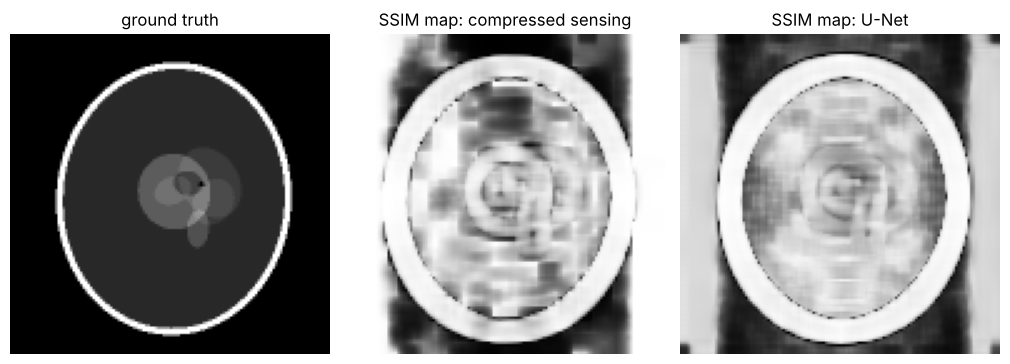

In [7]:
t = truth[test][0]
recons = reconstruct_all(t, lines)
maps = {}
for m in ["compressed sensing", "U-Net"]:
    value, maps[m] = structural_similarity(t, recons[m], data_range=1.0, full=True)
    print(f"{m:<20} SSIM {value:.3f}   NRMSE {nrmse(recons[m], t):.3f}")
show([t, maps["compressed sensing"], maps["U-Net"]],
     ["ground truth", "SSIM map: compressed sensing", "SSIM map: U-Net"], vmin=0, vmax=1)

On this phantom the two measures again disagree: the U-Net has the lower NRMSE, compressed sensing the higher SSIM.

In the maps, dark means low similarity. Both methods lose SSIM in the **empty background**, where the true image is zero: SSIM compares local contrast, so even tiny errors in a black region count heavily. This is a known weakness of SSIM, and many papers compute it only inside the object for that reason. Inside the head, compressed sensing loses SSIM in square **patches** (its Haar blocks), while the U-Net loses it more **evenly**, where it blurs, and in a dark ring just outside the skull. SSIM's average depends on how much of each kind of error there is, which is not the same as the squared error.

## Exercise 2: how small is too small?

square size               1      2      3      4      6
zero-filled            0.20   0.36   0.50   0.55   0.52
compressed sensing     0.48   0.69   0.70   0.83   0.66
U-Net                  0.10   0.14   0.19   0.27   0.45
unrolled network       0.13   0.41   0.62   0.77   0.92


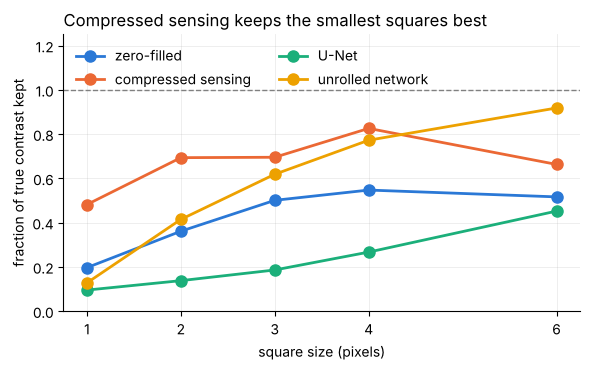

In [8]:
base = truth[test][3]
sizes = [1, 2, 3, 4, 6]
kept = {m: [] for m in METHODS}

def square_contrast(img, s):
    return img[60:60 + s, 50:50 + s].mean() - img[60 + s + 2:60 + 2 * s + 2, 50:50 + s].mean()

for s in sizes:
    img = base.copy()
    img[60:60 + s, 50:50 + s] += 0.35
    img = np.clip(img, 0, 1)
    recons = reconstruct_all(img, lines)
    true_contrast = square_contrast(img, s)
    for m in METHODS:
        kept[m].append(square_contrast(recons[m], s) / true_contrast)

print(f"{'square size':<20}" + "".join(f"{s:>7}" for s in sizes))
for m in METHODS:
    print(f"{m:<20}" + "".join(f"{v:>7.2f}" for v in kept[m]))

fig, ax = plt.subplots(figsize=(6, 3.8))
for m, color in zip(METHODS, COLORS):
    ax.plot(sizes, kept[m], "o-", color=color, linewidth=2, markersize=8, label=m)
ax.axhline(1, color="gray", linewidth=1, linestyle="--")
ax.set_xlabel("square size (pixels)")
ax.set_ylabel("fraction of true contrast kept")
ax.set_title("Compressed sensing keeps the smallest squares best", loc="left")
ax.set_xticks(sizes)
ax.set_ylim(0, 1.25)
ax.legend(frameon=False, ncol=2, loc="upper left")
tidy(ax)
plt.tight_layout()
plt.show()

**Every method loses contrast on small features**, and none keeps the full contrast even at 6 pixels.

- **Compressed sensing** keeps the smallest squares (1 to 3 pixels) best: a square is exactly the kind of feature Haar wavelets represent sparsely.
- **The unrolled network** catches up from about 4 pixels and is best at 6, but keeps very little of a 1-pixel square.
- **The U-Net** is the worst at every size, and keeps less contrast than zero-filling at every size.

(The curves are not perfectly smooth: each point is a single square at one position, measured against the pixels next to it. Averaging over several positions would give smoother curves.) Small findings are where reconstruction methods fail first, so they deserve their own tests.

## Exercise 3: one mask is not enough

In [9]:
per_seed = {m: [] for m in METHODS}
for seed in range(1, 6):
    mask_lines = variable_density_lines(N, 4, seed=seed)
    errors = {m: [] for m in METHODS}
    for i in range(10):
        recons = reconstruct_all(truth[test][i], mask_lines)
        for m in METHODS:
            errors[m].append(nrmse(recons[m], truth[test][i]))
    for m in METHODS:
        per_seed[m].append(np.mean(errors[m]))

print(f"{'method':<20}{'mean':>7}{'best':>7}{'worst':>7}   (NRMSE over mask seeds 1-5)")
for m in METHODS:
    v = np.array(per_seed[m])
    print(f"{m:<20}{v.mean():>7.3f}{v.min():>7.3f}{v.max():>7.3f}")

method                 mean   best  worst   (NRMSE over mask seeds 1-5)
zero-filled           0.329  0.307  0.360
compressed sensing    0.203  0.184  0.219
U-Net                 0.189  0.176  0.203
unrolled network      0.071  0.059  0.081


The ranking is the same for every mask seed, but the numbers move. The unrolled network's error ranges from about 0.06 to 0.08, a difference of more than a third; for compressed sensing and the U-Net the spread is smaller in relative terms. Both networks are worse than with their training mask (Section 5: U-Net 0.161, unrolled network 0.056), while zero-filling and compressed sensing, which were never trained on any mask, are about the same.

So the unrolled network is the most **mask-sensitive** in relative terms, though still the most accurate. A result reported for a single mask, especially the training mask, can make a method look more reliable than it is.

## Exercise 4: review a claim

Some questions a careful reviewer would ask (any five good ones are fine):

1. **Was compressed sensing tuned fairly?** Which λ, which transform, how many iterations? An untuned baseline makes any method look good.
2. **Which images were tested?** From the same scanners, hospital and patient group as the training data? Any **other** scanners, field strengths or contrasts?
3. **Which mask?** One mask or several? The same mask as in training? Does performance hold at other accelerations?
4. **Only SSIM?** What about NRMSE/PSNR, and especially **small lesions**: were abnormal cases included, and were they still visible?
5. **Noise and real data.** Were the "8×" scans real accelerated acquisitions, or fully sampled scans undersampled in software (as in this module)?
6. **Failure cases.** Where does the method fail? Are worst-case images shown?
7. **Radiologists.** Did blinded radiologists compare diagnoses on both kinds of image? "Can replace full-length scans" is a **clinical** claim; an SSIM value cannot support it on its own.
8. **Data consistency.** Does the network enforce consistency with the measured data, or can its output contradict the measurements?

The step from "high SSIM" to "can replace clinical scans" is the weakest part of the abstract: image similarity is not the same as diagnostic equivalence.